Install Packages and Set Up the Data

In [68]:
# Install these packages with the command below to run the code
# pip install pandas seaborn matplotlib

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

df = pd.read_csv("../Data/transformed_study_data.csv")

TEMP revision for static

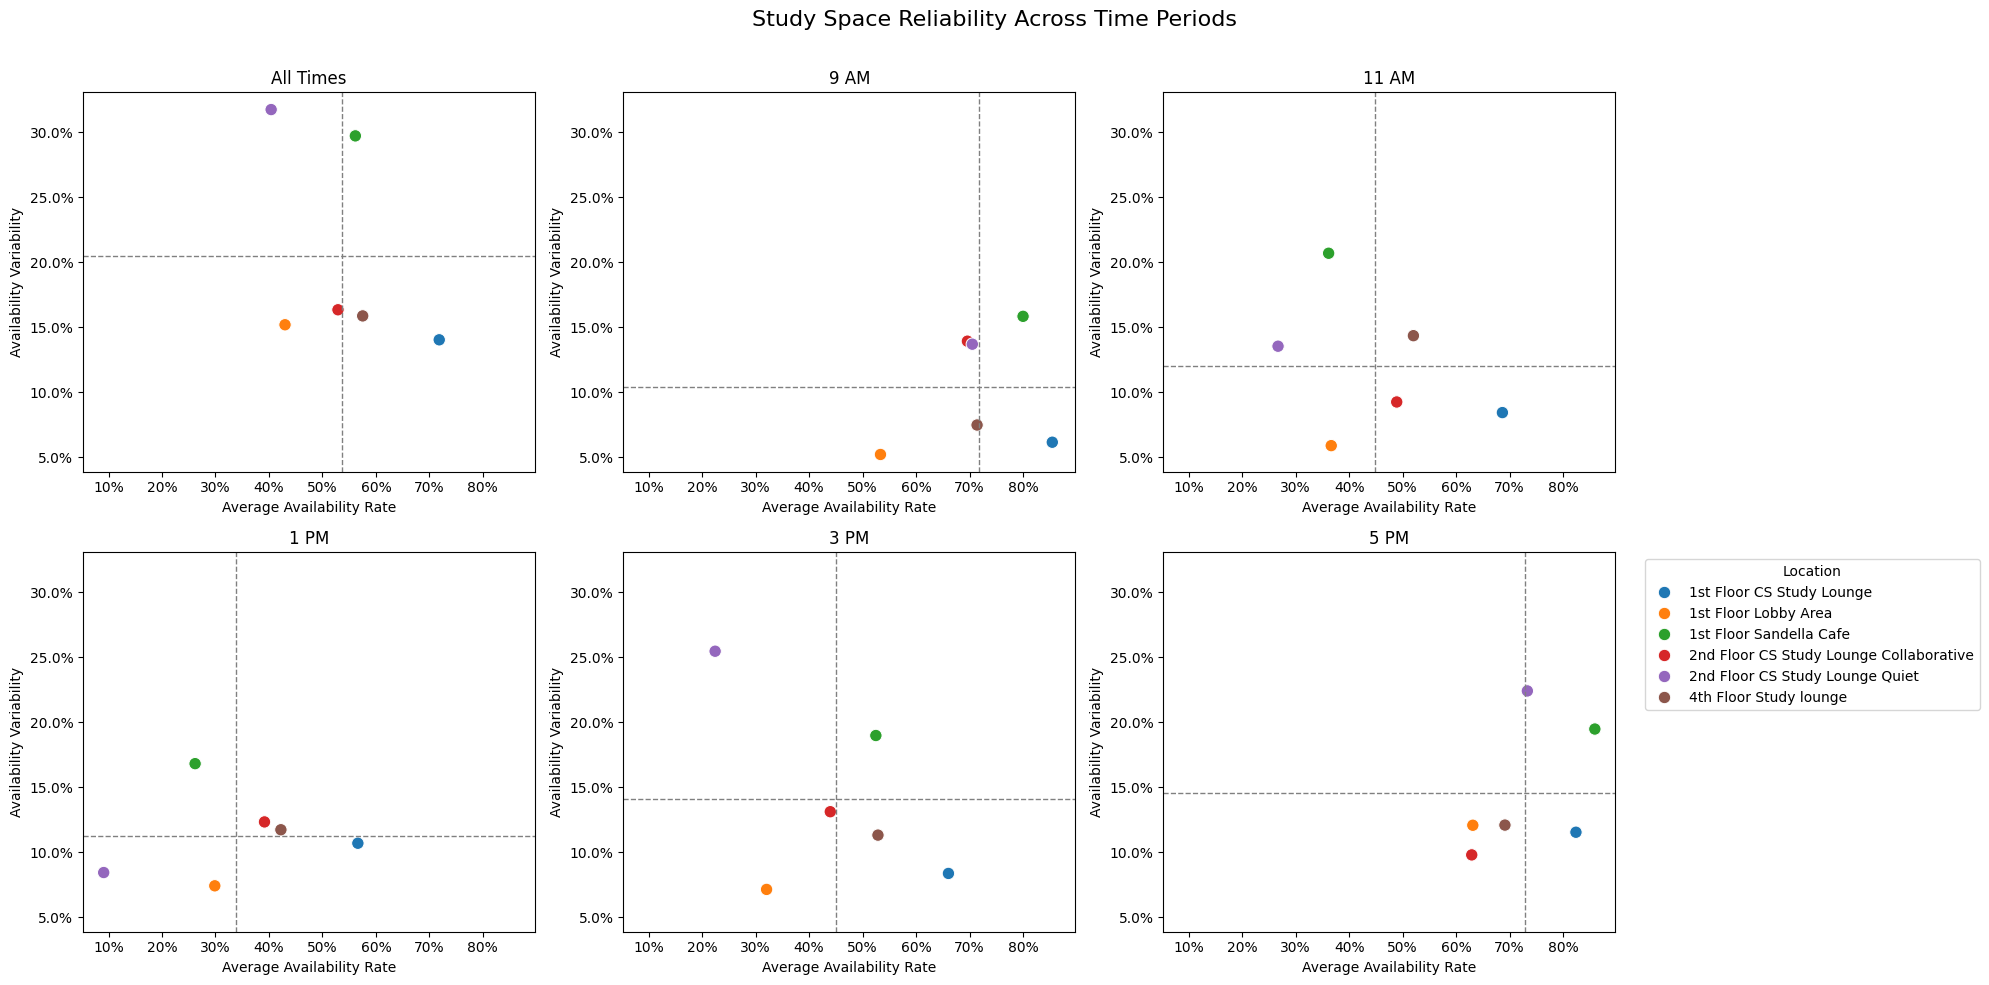

In [89]:
# Ensure time values are treated consistently as strings
df["time"] = df["time"].astype(str)

# Calculate overall reliability metrics across all time periods
all_data = (
    df.groupby("location")
      .agg(
          avg_availability=("availability_rate", "mean"),
          availability_std=("availability_rate", "std"),
          avg_occupancy=("occupancy_rate", "mean"),
          traffic_level=("traffic_level", "first")
      )
      .reset_index()
)


# Calculate reliability metrics for each individual time period
time_summaries = {}

for t in ["9:00", "11:00", "13:00", "15:00", "17:00"]:
    time_summaries[t] = (
        df[df["time"] == t]
        .groupby("location")
        .agg(
            avg_availability=("availability_rate", "mean"),
            availability_std=("availability_rate", "std"),
            avg_occupancy=("occupancy_rate", "mean"),
            traffic_level=("traffic_level", "first")
        )
        .reset_index()
    )


# Create a 2x3 grid of small multiple scatterplots
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(20, 10),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

# Pair each dataset with its corresponding subplot title
plot_data = [
    ("All Times", all_data),
    ("9 AM", time_summaries["9:00"]),
    ("11 AM", time_summaries["11:00"]),
    ("1 PM", time_summaries["13:00"]),
    ("3 PM", time_summaries["15:00"]),
    ("5 PM", time_summaries["17:00"])
]


# Generate a scatterplot for each time period
for ax, (title, data) in zip(axes, plot_data):

    # Compute subplot reference values
    avg_x = data["avg_availability"].mean()
    avg_y = data["availability_std"].mean()

    sns.scatterplot(
        data=data,
        x="avg_availability",
        y="availability_std",
        hue="location",
        s=80,
        ax=ax
    )

    ax.set_title(title, fontsize=12)

    # Add mean reference lines for availability and variability
    ax.axvline(
        avg_x,
        linestyle="--",
        color="gray",
        linewidth=1
    )

    ax.axhline(
        avg_y,
        linestyle="--",
        color="gray",
        linewidth=1
    )

    # Display values as percentages
    ax.xaxis.set_major_formatter(
        ticker.PercentFormatter(1.0)
    )

    ax.yaxis.set_major_formatter(
        ticker.PercentFormatter(1.0)
    )

# Show axis labels and tick labels on every subplot
for ax in axes:
    ax.tick_params(axis="x", labelbottom=True)
    ax.tick_params(axis="y", labelleft=True)

    ax.set_xlabel("Average Availability Rate")
    ax.set_ylabel("Availability Variability")

    ax.xaxis.label.set_visible(True)
    ax.yaxis.label.set_visible(True)


# Remove duplicate legends from the first five plots
for ax in axes[:-1]:
    if ax.get_legend() is not None:
        ax.get_legend().remove()

# Keep one shared legend
axes[-1].legend(
    title="Location",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)


# Add an overall figure title
plt.suptitle(
    "Study Space Reliability Across Time Periods", 
    fontsize=16
)

# Adjust spacing to prevent overlap
plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()

Static Visualization Implementation

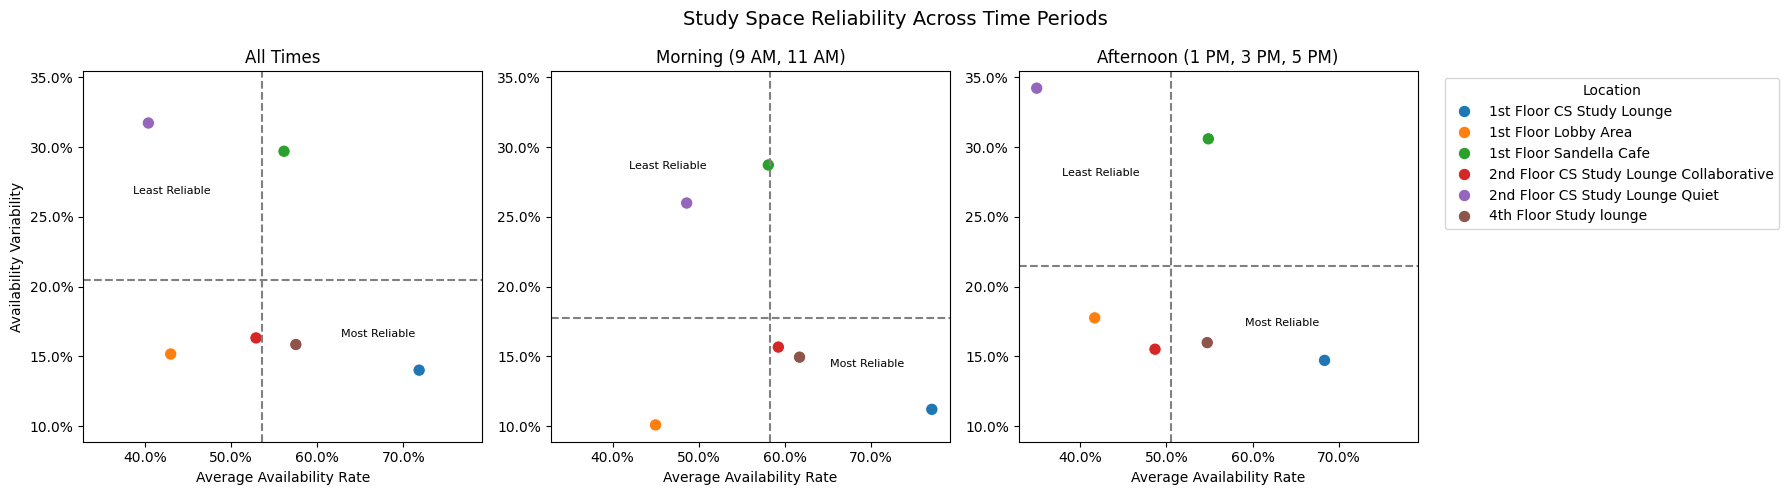

In [69]:
def assign_time_period(time):
    if time in ["9:00", "11:00"]:
        return "Morning"
    else:
        return "Afternoon"

df["time_period"] = df["time"].astype(str).apply(assign_time_period)

# ALL TIMES
all_data = (
    df.groupby("location")
      .agg(
          avg_availability=("availability_rate", "mean"),
          availability_std=("availability_rate", "std"),
          avg_occupancy=("occupancy_rate", "mean"),
          traffic_level=("traffic_level", "first")
      )
      .reset_index()
)

# MORNING
morning_data = (
    df[df["time_period"] == "Morning"]
      .groupby("location")
      .agg(
          avg_availability=("availability_rate", "mean"),
          availability_std=("availability_rate", "std"),
          avg_occupancy=("occupancy_rate", "mean"),
          traffic_level=("traffic_level", "first")
      )
      .reset_index()
)

# AFTERNOON
afternoon_data = (
    df[df["time_period"] == "Afternoon"]
      .groupby("location")
      .agg(
          avg_availability=("availability_rate", "mean"),
          availability_std=("availability_rate", "std"),
          avg_occupancy=("occupancy_rate", "mean"),
          traffic_level=("traffic_level", "first")
      )
      .reset_index()
)

# QUADRANT REFERENCE VALUES
all_x = all_data["avg_availability"].mean()
all_y = all_data["availability_std"].mean()

morning_x = morning_data["avg_availability"].mean()
morning_y = morning_data["availability_std"].mean()

afternoon_x = afternoon_data["avg_availability"].mean()
afternoon_y = afternoon_data["availability_std"].mean()

# CREATE STATIC SMALL MULTIPLES
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

# ALL TIMES
sns.scatterplot(
    data=all_data,
    x="avg_availability",
    y="availability_std",
    hue="location",
    s=80,
    ax=axes[0]
)
axes[0].set_title("All Times")
axes[0].set_xlabel("Average Availability Rate")
axes[0].set_ylabel("Availability Variability")
axes[0].axvline(all_x, linestyle="--", color="gray")
axes[0].axhline(all_y, linestyle="--", color="gray")
axes[0].text(
    all_x * 1.17,
    all_y * 0.8,
    "Most Reliable",
    fontsize=8,
)
axes[0].text(
    all_x * 0.72,
    all_y * 1.3,
    "Least Reliable",
    fontsize=8,
)

# MORNING
sns.scatterplot(
    data=morning_data,
    x="avg_availability",
    y="availability_std",
    hue="location",
    s=80,
    ax=axes[1]
)
axes[1].set_title("Morning (9 AM, 11 AM)")
axes[1].set_xlabel("Average Availability Rate")
axes[1].set_ylabel("Availability Variability")
axes[1].axvline(morning_x, linestyle="--", color="gray")
axes[1].axhline(morning_y, linestyle="--", color="gray")
axes[1].text(
    morning_x * 1.12,
    morning_y * 0.8,
    "Most Reliable",
    fontsize=8
)
axes[1].text(
    morning_x * 0.72,
    morning_y * 1.6,
    "Least Reliable",
    fontsize=8
)

# AFTERNOON
sns.scatterplot(
    data=afternoon_data,
    x="avg_availability",
    y="availability_std",
    hue="location",
    s=80,
    ax=axes[2]
)
axes[2].set_title("Afternoon (1 PM, 3 PM, 5 PM)")
axes[2].set_xlabel("Average Availability Rate")
axes[2].set_ylabel("Availability Variability")
axes[2].axvline(afternoon_x, linestyle="--", color="gray")
axes[2].axhline(afternoon_y, linestyle="--", color="gray")
axes[2].text(
    afternoon_x * 1.17,
    afternoon_y * 0.8,
    "Most Reliable",
    fontsize=8
)
axes[2].text(
    afternoon_x * 0.75,
    afternoon_y * 1.3,
    "Least Reliable",
    fontsize=8
)

# FORMAT AXES
for ax in axes:
    ax.xaxis.set_major_formatter(
        ticker.PercentFormatter(1.0)
    )
    ax.yaxis.set_major_formatter(
        ticker.PercentFormatter(1.0)
    )

# Force y tick labels to appear on all plots
for ax in axes:
    ax.tick_params(axis="y", labelleft=True)

# Remove duplicate legends
axes[0].get_legend().remove()
axes[1].get_legend().remove()

# Keep one legend
axes[2].legend(
    title="Location",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.suptitle(
    "Study Space Reliability Across Time Periods",
    fontsize=14
)

plt.tight_layout()
plt.show()

Install Package

In [70]:
# Install this package with the command below to run the code
# pip install plotly

import plotly.graph_objects as go

Interactive Visualization Implementation

In [71]:
# pip install --upgrade nbformat

locations = all_data["location"].tolist()

color_map = {
    "1st Floor CS Study Lounge": "#1f77b4",
    "1st Floor Lobby Area": "#ff7f0e",
    "1st Floor Sandella Cafe": "#2ca02c",
    "2nd Floor CS Study Lounge Collaborative": "#d62728",
    "2nd Floor CS Study Lounge Quiet": "#9467bd",
    "4th Floor Study lounge": "#8c564b"
}

fig = go.Figure()


# CREATE ONE TRACE PER LOCATION
for location in locations:

    row = all_data[
        all_data["location"] == location
    ].iloc[0]

    fig.add_trace(
        go.Scatter(
            x=[row["avg_availability"]],
            y=[row["availability_std"]],
            mode="markers",
            name=location,
            marker=dict(
                size=8,
                color=color_map[location]
            ),
            customdata=[[
                row["location"]
            ]],
            hovertemplate=
            "<b>%{customdata[0]}</b><br><br>"
            "Average Availability: %{x:.1%}<br>"
            "Availability Variability: %{y:.1%}<br>"
            "<extra></extra>"
        )
    )


# CREATE DROPDOWN DATA
all_x = []
all_y = []
all_custom = []

morning_x = []
morning_y = []
morning_custom = []

afternoon_x = []
afternoon_y = []
afternoon_custom = []

for location in locations:

    all_row = all_data[
        all_data["location"] == location
    ].iloc[0]

    morning_row = morning_data[
        morning_data["location"] == location
    ].iloc[0]

    afternoon_row = afternoon_data[
        afternoon_data["location"] == location
    ].iloc[0]

    all_x.append(all_row["avg_availability"])
    all_y.append(all_row["availability_std"])
    all_custom.append([
        all_row["location"]
    ])

    morning_x.append(morning_row["avg_availability"])
    morning_y.append(morning_row["availability_std"])
    morning_custom.append([
        morning_row["location"]
    ])

    afternoon_x.append(afternoon_row["avg_availability"])
    afternoon_y.append(afternoon_row["availability_std"])
    afternoon_custom.append([
        afternoon_row["location"],
    ])


# DROPDOWN
fig.update_layout(
    updatemenus=[
        dict(
            buttons=[
                dict(
                    label="All Times",
                    method="restyle",
                    args=[
                        {
                            "x": [[x] for x in all_x],
                            "y": [[y] for y in all_y],
                            "customdata": [[c] for c in all_custom]
                        }
                    ]
                ),
                dict(
                    label="Morning (9 AM, 11 AM)",
                    method="restyle",
                    args=[
                        {
                            "x": [[x] for x in morning_x],
                            "y": [[y] for y in morning_y],
                            "customdata": [[c] for c in morning_custom]
                        }
                    ]
                ),
                dict(
                    label="Afternoon (1 PM, 3 PM, 5 PM)",
                    method="restyle",
                    args=[
                        {
                            "x": [[x] for x in afternoon_x],
                            "y": [[y] for y in afternoon_y],
                            "customdata": [[c] for c in afternoon_custom]
                        }
                    ]
                )
            ],
            direction="down",
            x=0.95,
            y=1.18
        )
    ]
)


# QUADRANTS
avg_x = all_data["avg_availability"].mean()
avg_y = all_data["availability_std"].mean()

fig.add_vline(
    x=avg_x,
    line_dash="dash",
    line_color="gray"
)

fig.add_hline(
    y=avg_y,
    line_dash="dash",
    line_color="gray"
)

fig.add_annotation(
    x=avg_x * 1.2,
    y=avg_y * 0.85,
    text="<b>Most Reliable</b>",
    showarrow=False
)

fig.add_annotation(
    x=avg_x * 0.87,
    y=avg_y * 1.38,
    text="<b>Least Reliable</b>",
    showarrow=False
)


# LAYOUT
fig.update_layout(
    title="Reliability of Seat Availability",
    xaxis_title="Average Availability Rate",
    yaxis_title="Availability Variability (Standard Deviation)",
    legend_title_text="Location"
)

fig.update_xaxes(tickformat=".0%")
fig.update_yaxes(tickformat=".0%")

fig.show()

In [72]:
morning_data

,location,avg_availability,availability_std,avg_occupancy,traffic_level
0,1st Floor CS Study Lounge,0.770633,0.112130,0.229367,Low Traffic
1,1st Floor Lobby Area,0.449967,0.100987,0.550033,High Traffic
2,1st Floor Sandella Cafe,0.580833,0.287192,0.419167,High Traffic
3,2nd Floor CS Study Lounge Collaborative,0.592467,0.156740,0.407533,Low Traffic
4,2nd Floor CS Study Lounge Quiet,0.486100,0.259924,0.513900,Low Traffic
5,4th Floor Study lounge,0.617100,0.149509,0.382900,Low Traffic


In [73]:
afternoon_data

,location,avg_availability,availability_std,avg_occupancy,traffic_level
0,1st Floor CS Study Lounge,0.683622,0.147208,0.316378,Low Traffic
1,1st Floor Lobby Area,0.416800,0.177658,0.583200,High Traffic
2,1st Floor Sandella Cafe,0.548711,0.305936,0.451289,High Traffic
3,2nd Floor CS Study Lounge Collaborative,0.486822,0.155193,0.513178,Low Traffic
4,2nd Floor CS Study Lounge Quiet,0.349489,0.342215,0.650511,Low Traffic
5,4th Floor Study lounge,0.547444,0.159912,0.452556,Low Traffic
